# Detección de deslizamientos con Prithvi

**Grupo 2 · Inteligencia Artificial**  
**Profesor:** Eduardo Enrique Zurek Varela  
**Entrega:** 23 de noviembre de 2026  
**Ejecución y revisión:** 17 de noviembre de 2026  
**Repositorio:** https://github.com/Charlsz/prithvi-deslizamiento

## Resumen

Evaluamos el flujo docente de segmentación binaria con Prithvi EO 1.0 100M congelado y Random Forest por parches, sobre cuatro imágenes de entrenamiento y dos de prueba de Landslide4Sense. El modelo y la línea base constante obtuvieron IoU y F1 de deslizamiento iguales a cero. El diagnóstico identificó 919 píxeles positivos en entrenamiento, pero ningún parche etiquetado como positivo tras la agregación mayoritaria. El experimento documenta una limitación del flujo ante objetos pequeños; no permite concluir que Prithvi carezca de capacidad para detectar deslizamientos. La confirmación docente del contrato de entrada sigue pendiente.

La ampliación complementaria de la sección 12 incorpora entrenamiento y validación separados y obtiene resultados distintos de cero sobre 32 escenas nuevas. Su mejor F1 medio entre las variantes con Prithvi seleccionadas en validación es 0.3068; se mantiene la distinción entre el flujo docente y las extensiones.

## 1 Contribuciones y uso de IA

Los nueve integrantes desarrollaron el proyecto de manera colaborativa, según la declaración del grupo. La contribución declarada es compartida; no se atribuyen funciones individuales que no hayan sido confirmadas.

| Integrante | Contribución declarada |
| --- | --- |
| Bauz Villa, Juan | Trabajo colaborativo en el desarrollo del proyecto |
| Cera Moran, Daniel | Trabajo colaborativo en el desarrollo del proyecto |
| Galvis Pajaro, Carlos | Trabajo colaborativo en el desarrollo del proyecto |
| Jimenez Atencia, Cher | Trabajo colaborativo en el desarrollo del proyecto |
| Mercado Martinez, Sebastian | Trabajo colaborativo en el desarrollo del proyecto |
| Molina Vega, Dayana | Trabajo colaborativo en el desarrollo del proyecto |
| Romero Pemberthy, Juan | Trabajo colaborativo en el desarrollo del proyecto |
| Ruiz Espitia, Kevin | Trabajo colaborativo en el desarrollo del proyecto |
| Vargas Becerra, Natalia | Trabajo colaborativo en el desarrollo del proyecto |

Se utilizó asistencia de IA para revisión del código, depuración, organización de entregables, verificación y redacción. Las cifras proceden de archivos y ejecución reales. Cada integrante debe poder explicar el proceso y el resultado, de acuerdo con el enunciado.

## 2 Problema y objetivo

La entrada es una imagen multiespectral; la salida, una máscara binaria que distingue fondo (0) y deslizamiento observado (1). El objetivo es medir si las representaciones de un encoder geoespacial congelado, con una cabeza ligera, superan una predicción constante. La hipótesis no se sostiene en este piloto. Detectar áreas ya afectadas es distinto de estimar susceptibilidad del terreno o predecir cuándo ocurrirá un evento.

## 3 Marco teórico

Un modelo fundacional aprende representaciones reutilizables mediante preentrenamiento a gran escala. Prithvi 1.0 emplea un transformer y un objetivo autosupervisado de autoencoder enmascarado, MAE [1], [2]. La imagen se convierte en tokens de parches; la atención relaciona sus características. El preentrenamiento reconstruye regiones ocultas, pero no proporciona por sí solo etiquetas de deslizamiento. Una cabeza de predicción debe aprender esa correspondencia con referencias de la tarea.

Las bandas multiespectrales describen respuestas distintas de la superficie. Su orden y escala forman parte del contrato de entrada y no son intercambiables. La transferencia reutiliza el encoder; el fine-tuning actualizaría sus pesos. Aquí todos los pesos de Prithvi están congelados y solo se entrena un Random Forest. La inferencia aplica el modelo ya configurado a una imagen. No se usa la reconstrucción del MAE como máscara de segmentación.

Utilizamos Prithvi EO 1.0 100M, no Prithvi 2.0. El artículo de la segunda versión es lectura contextual [5], no la identificación de los pesos ejecutados. La codificación posicional fija se regenera para una fecha y se comprueba que solo falten esas claves al cargar el checkpoint.

## 4 Datos y contrato de entrada

La descarga usa el espejo sasmit545/Landslide4sense de Hugging Face [4], con revisión fija 8508a55feceb5653a085d6be64ef9217710f7c00. El conjunto de origen combina canales de Sentinel 2 con pendiente y elevación de ALOS PALSAR; su documentación describe recortes de 128 por 128 píxeles a aproximadamente 10 m [3]. Los HDF5 examinados no tienen atributos de fecha, CRS, transformación geográfica o evento. Por tanto, no se asignan fechas ni regiones específicas a estas seis imágenes.

El lector suministrado selecciona índices base cero [1, 2, 3, 8, 10, 11] y excluye los dos canales auxiliares. No se da por comprobado que el índice 8 sea B8A: la descripción pública enumera 12 canales ópticos sin resolver inequívocamente esa correspondencia. Se conserva el flujo docente y se declara pendiente su confirmación sobre bandas, escala, normalización y pesos, exigida por la ficha. No se aplica una conversión inventada a reflectancia física.

La normalización es z score por banda, calculada exclusivamente sobre posiciones válidas de entrenamiento. Sus medias y desviaciones se guardan en normalizacion.json. Este ajuste no equivale necesariamente al preprocesamiento de HLS utilizado en el preentrenamiento. La visualización RGB usa rojo, verde y azul del lector y un estiramiento entre percentiles 2 y 98 solo para mostrar la imagen; no cambia la entrada del modelo.

| Partición | Archivo de imagen | Píxeles válidos | Deslizamiento |
| --- | --- | ---: | ---: |
| Train | image_1.h5 | 16384 | 405 |
| Train | image_10.h5 | 16384 | 0 |
| Train | image_100.h5 | 16384 | 479 |
| Train | image_1000.h5 | 16384 | 35 |
| Test | image_1.h5 | 16384 | 33 |
| Test | image_10.h5 | 16384 | 13 |

Se eligen los primeros archivos por orden lexicográfico en cada partición, conservando el piloto 4/2 del notebook. Los mismos nombres en train y test no significan el mismo archivo: sus SHA256 difieren. No hay imágenes idénticas por hash entre particiones, pero esto no acredita independencia geográfica o por evento. No se usa una partición de validación ni se buscan hiperparámetros.

Cada imagen produce un tensor de 6 canales y una fecha. El relleno edge completa 128 a 224 píxeles sin interpolar etiquetas. La referencia vale -1 en el relleno y en posiciones inválidas. Por escena se ignoran 33792 posiciones y se evalúan 16384. La ausencia de datos no se considera fondo. El contexto artificial del relleno puede afectar al encoder aunque no se puntúe.



## Ejecución reproducible
Ejecutar todas las celdas en orden. El cuaderno es autónomo y descarga pesos y el subconjunto real. La instalación se realiza solo si faltan dependencias. Los resultados guardados se muestran después de generarlos.

In [1]:
import importlib.util
needed = ['torch', 'torchvision', 'timm', 'huggingface_hub', 'rasterio', 'yaml', 'einops', 'h5py', 'sklearn', 'requests', 'pandas', 'matplotlib']
if any(importlib.util.find_spec(name) is None for name in needed):
    %pip -q install torch torchvision "timm==0.9.2" "huggingface_hub>=0.25,<1" "rasterio>=1.3,<2" "PyYAML>=6,<7" "einops>=0.7,<1" "h5py>=3,<4" "scikit-learn>=1.3,<2" requests pandas matplotlib
else:
    print('Dependencias disponibles; versiones registradas en procedencia.json.')
import matplotlib
matplotlib.use('Agg')


Dependencias disponibles; versiones registradas en procedencia.json.


### Módulo docente con correcciones de compatibilidad

In [2]:
from pathlib import Path
MODULE_TEXT = '"""Soporte docente experimental para Prithvi. No incluye pesos ni escenas reales.\nLas descargas se realizan en Colab. No validado de extremo a extremo.\n"""\nfrom pathlib import Path\nimport json, re, hashlib, tarfile, shutil, warnings, io, time\nimport numpy as np\nimport requests\n\nSOURCES = {\n \'inundaciones\': \'https://github.com/cloudtostreet/Sen1Floods11\',\n \'quemadas\': \'https://huggingface.co/datasets/ibm-nasa-geospatial/hls_burn_scars\',\n \'cultivos\': \'https://huggingface.co/datasets/ibm-nasa-geospatial/multi-temporal-crop-classification\',\n \'deslizamientos\': \'https://huggingface.co/datasets/sasmit545/Landslide4sense\',\n}\n\ndef save_json(path, data):\n    Path(path).write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding="utf-8")\n\ndef sha256(path):\n    h=hashlib.sha256()\n    with open(path,\'rb\') as f:\n        for b in iter(lambda:f.read(1048576),b\'\'): h.update(b)\n    return h.hexdigest()\n\ndef get(url,path,max_mb=250):\n    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)\n    if path.exists() and path.stat().st_size>0:return path\n    temp=path.with_suffix(path.suffix+\'.part\')\n    try:\n        with requests.get(url,stream=True,timeout=(30,120)) as r:\n            r.raise_for_status(); size=0\n            with open(temp,\'wb\') as f:\n                for b in r.iter_content(1024*1024):\n                    size+=len(b)\n                    if size>max_mb*1024**2:raise RuntimeError(\'Descarga supera el límite por archivo.\')\n                    f.write(b)\n        temp.replace(path)\n    finally:\n        if temp.exists():temp.unlink()\n    return path\n\ndef sample_key(path):\n    stem=Path(path).name.lower()\n    for suffix in [\'.tiff\',\'.tif\',\'.h5\',\'.hdf5\']:\n        if stem.endswith(suffix):stem=stem[:-len(suffix)]\n    for token in [\'_merged\',\'.mask\',\'_mask\',\'_label\',\'_s2hand\',\'_labelhand\']:\n        stem=stem.replace(token,\'\')\n    return stem\n\ndef pair_tifs(directory):\n    files=sorted(Path(directory).rglob(\'*.tif\'))\n    labels={sample_key(f):f for f in files if any(s in f.name.lower() for s in [\'mask\',\'label\'])}\n    return [(f,labels[sample_key(f)]) for f in files\n            if not any(s in f.name.lower() for s in [\'mask\',\'label\']) and sample_key(f) in labels]\n\nclass LimitedReader:\n    def __init__(self, raw, max_bytes):self.raw=raw; self.maximum=max_bytes; self.total=0\n    def read(self,size=-1):\n        b=self.raw.read(size); self.total+=len(b)\n        if self.total>self.maximum:\n            raise RuntimeError(\'El tar excede el presupuesto de red. No se completó el subconjunto. Aumentar max_stream_mb solo tras revisar tamaño y conexión; no hay garantía de descarga pequeña.\')\n        return b\n\ndef subset_archive(url, root, requested, combined=False, max_stream_mb=512):\n    """Extrae pares sin descomprimir rutas del tar. Conserva pocos archivos.\n    Leer gzip es secuencial: puede transferir mucho aunque se guarde poco.\n    """\n    root=Path(root); root.mkdir(parents=True,exist_ok=True)\n    targets={\'train\':requested[0],\'test\':requested[1]} if combined else requested\n    kept={s:{\'image\':set(),\'label\':set()} for s in targets}\n    with requests.get(url,stream=True,timeout=(30,120)) as response:\n        response.raise_for_status(); response.raw.decode_content=True\n        counter=LimitedReader(response.raw,int(max_stream_mb*1024**2))\n        with tarfile.open(fileobj=counter,mode=\'r|gz\') as tar:\n            for member in tar:\n                if not member.isfile() or not member.name.lower().endswith((\'.tif\',\'.tiff\')):continue\n                low=member.name.lower()\n                if combined:\n                    if re.search(r\'(^|[/_])(?:training|train)([/_]|$)\',low): split=\'train\'\n                    elif re.search(r\'(^|[/_])(?:validation|valid|val|test)([/_]|$)\',low): split=\'test\'\n                    else:continue\n                else:split=next(iter(targets))\n                target=targets[split]\n                if len(pair_tifs(root/split))>=target:continue\n                kind=\'label\' if any(t in Path(low).name for t in [\'mask\',\'label\']) else \'image\'\n                key=sample_key(low)\n                other=\'image\' if kind==\'label\' else \'label\'\n                # Guardado acotado; si se listan antes imágenes que máscaras,\n                # conservar hasta 4*n para permitir el emparejamiento.\n                if key not in kept[split][other] and len(kept[split][kind])>=4*target:continue\n                dest=root/split/Path(member.name).name; dest.parent.mkdir(exist_ok=True)\n                stream=tar.extractfile(member)\n                with open(dest,\'wb\') as out:shutil.copyfileobj(stream,out)\n                kept[split][kind].add(key)\n                if all(len(pair_tifs(root/s))>=n for s,n in targets.items()):break\n        print(\'Bytes comprimidos leídos:\',counter.total)\n    result={s:pair_tifs(root/s)[:n] for s,n in targets.items()}\n    for s,n in targets.items():\n        if len(result[s])<n:\n            raise RuntimeError(f\'Solo se emparejaron {len(result[s])}/{n} en {s}. Revisar nombres/estructura del tar; no se sustituyen datos.\')\n    return result\n\ndef download_flood(root,ntrain,ntest):\n    import pandas as pd\n    root=Path(root); base=\'https://storage.googleapis.com/sen1floods11/v1.1/\'\n    result={}\n    for split,tag,n in [(\'train\',\'train\',ntrain),(\'test\',\'test\',ntest)]:\n        csvname=f\'flood_{tag}_data.csv\'\n        alternatives=[base+\'splits/flood_handlabeled/\'+csvname,\n          \'https://raw.githubusercontent.com/cloudtostreet/Sen1Floods11/master/splits/flood_handlabeled/\'+csvname]\n        content=None\n        for url in alternatives:\n            rr=requests.get(url,timeout=60)\n            if rr.status_code==200:content=rr.text;break\n        if content is None:raise RuntimeError(\'No se pudo recuperar la partición oficial Sen1Floods11.\')\n        (root).mkdir(parents=True,exist_ok=True); (root/csvname).write_text(content)\n        ids=[]\n        for line in content.splitlines():\n            hit=re.search(r\'([A-Za-z]+_\\d+)_S[12]Hand\\.tif\',line)\n            if hit and hit.group(1) not in ids:ids.append(hit.group(1))\n        if len(ids)<n:raise RuntimeError(\'La estructura del CSV cambió: revisar antes de continuar.\')\n        rows=[]\n        for sample in ids[:n]:\n            image=get(base+\'data/flood_events/HandLabeled/S2Hand/\'+sample+\'_S2Hand.tif\',root/split/(sample+\'_S2Hand.tif\'))\n            label=get(base+\'data/flood_events/HandLabeled/LabelHand/\'+sample+\'_LabelHand.tif\',root/split/(sample+\'_LabelHand.tif\'))\n            rows.append((image,label))\n        result[split]=rows\n    return result\n\ndef download_landslide(root,ntrain,ntest):\n    from huggingface_hub import HfApi,hf_hub_download\n    repo=\'sasmit545/Landslide4sense\'; api=HfApi()\n    rev=\'8508a55feceb5653a085d6be64ef9217710f7c00\' # revisión de los datos del piloto\n    names=api.list_repo_files(repo,repo_type=\'dataset\',revision=rev)\n    result={}\n    for split,n in [(\'train\',ntrain),(\'test\',ntest)]:\n        images=sorted([f for f in names if f.startswith(\'images/\'+split+\'/\') and f.endswith(\'.h5\')])\n        masks={re.findall(r\'\\d+\',Path(f).stem)[-1]:f for f in names\n               if f.startswith(\'annotations/\'+split+\'/\') and f.endswith(\'.h5\')}\n        rows=[]\n        for im in images:\n            idx=re.findall(r\'\\d+\',Path(im).stem)[-1]\n            if idx not in masks:continue\n            a=hf_hub_download(repo,filename=im,repo_type=\'dataset\',revision=rev,local_dir=str(root))\n            b=hf_hub_download(repo,filename=masks[idx],repo_type=\'dataset\',revision=rev,local_dir=str(root))\n            rows.append((Path(a),Path(b)))\n            if len(rows)==n:break\n        if len(rows)<n:raise RuntimeError(\'Estructura HDF5 diferente de la documentada; revisar el inventario.\')\n        result[split]=rows\n    save_json(Path(root)/\'revision_datos.json\',{\'repo\':repo,\'revision\':rev})\n    return result\n\ndef download_data(task,root,ntrain=4,ntest=2,max_stream_mb=512):\n    from huggingface_hub import HfApi,hf_hub_url\n    root=Path(root);root.mkdir(parents=True,exist_ok=True)\n    if task==\'inundaciones\': result=download_flood(root,ntrain,ntest)\n    elif task==\'deslizamientos\':result=download_landslide(root,ntrain,ntest)\n    else:\n        repo={\'quemadas\':\'ibm-nasa-geospatial/hls_burn_scars\',\n              \'cultivos\':\'ibm-nasa-geospatial/multi-temporal-crop-classification\'}[task]\n        api=HfApi();revision=api.dataset_info(repo).sha\n        files=api.list_repo_files(repo,repo_type=\'dataset\',revision=revision)\n        print(\'Inventario del dataset:\',files)\n        if task==\'quemadas\':\n            archive=next((f for f in files if f.endswith(\'hls_burn_scars.tar.gz\')),None)\n            if archive is None:raise RuntimeError(\'No se encontró el tar documentado de Burn Scars.\')\n            result=subset_archive(hf_hub_url(repo,archive,repo_type=\'dataset\',revision=revision),root,\n                                  (ntrain,ntest),combined=True,max_stream_mb=max_stream_mb)\n        else:\n            result={}\n            for split,name,n in [(\'train\',\'training_chips.tgz\',ntrain),(\'test\',\'validation_chips.tgz\',ntest)]:\n                if name not in files:raise RuntimeError(f\'Falta {name}; revisar inventario.\')\n                result.update(subset_archive(hf_hub_url(repo,name,repo_type=\'dataset\',revision=revision),root,\n                         {split:n},combined=False,max_stream_mb=max_stream_mb))\n        save_json(root/\'revision_datos.json\',{\'repo\':repo,\'revision\':revision})\n    manifest=[]\n    for split,pairs in result.items():\n        for im,lab in pairs:\n            manifest.append({\'split\':split,\'image\':str(im),\'label\':str(lab),\n                             \'image_sha256\':sha256(im),\'label_sha256\':sha256(lab)})\n    save_json(root/\'manifest.json\',{\'task\':task,\'source\':SOURCES[task],\n          \'note\':\'Subconjunto por orden, no por desempeño; train/test según proveedor. En cultivos, validation se usa como evaluación sin ajustar decisiones.\',\n          \'samples\':manifest})\n    return result\n\ndef read_sample(task, image_path, label_path, crop_layout=\'CT\',side=224):\n    """Retorna imagen C,T,H,W y etiqueta H,W. No remuestrea etiquetas.\n    Orden óptico asumido/documentado en el notebook: azul,verde,rojo,B8A,SWIR1,SWIR2.\n    """\n    import rasterio,h5py\n    if task==\'deslizamientos\':\n        with h5py.File(image_path,\'r\') as f:\n            keys=list(f.keys());key=\'img\' if \'img\' in f else \'image\' if \'image\' in f else None\n            if key is None:raise RuntimeError(f\'Clave HDF5 no reconocida: {keys}\')\n            im=np.asarray(f[key],dtype=np.float32)\n        if im.shape[-1]==14:im=im.transpose(2,0,1)\n        if im.shape[0]!=14:raise ValueError(\'Se esperaban 14 canales Landslide4Sense.\')\n        im=im[[1,2,3,8,10,11]][:,None] # selección docente; identidad de B8A pendiente de confirmar\n        with h5py.File(label_path,\'r\') as f:\n            if \'mask\' not in f:raise RuntimeError(\'No existe la clave mask en la referencia.\')\n            label=np.asarray(f[\'mask\']).squeeze().astype(np.int64)\n    else:\n        with rasterio.open(image_path) as f:\n            arr=f.read(masked=True).astype(np.float32).filled(np.nan)\n            ref_crs,ref_transform=f.crs,f.transform\n        with rasterio.open(label_path) as f:\n            label=f.read(1,masked=True).astype(np.int64).filled(-1)\n            if f.crs!=ref_crs or f.transform!=ref_transform:raise ValueError(\'Imagen y etiqueta geográficamente desalineadas.\')\n        if task==\'inundaciones\':\n            if arr.shape[0]!=13:raise ValueError(\'Se esperan las 13 bandas S2Hand en orden B01..B12, incluyendo B8A.\')\n            im=arr[[1,2,3,8,11,12]][:,None]\n        elif task==\'quemadas\':\n            if arr.shape[0]!=6:raise ValueError(\'Se esperan 6 bandas HLS.\')\n            im=arr[:,None]\n        else:\n            if arr.shape[0]!=18:raise ValueError(\'Se esperan 18 canales (6 bandas × 3 fechas).\')\n            if crop_layout==\'CT\':im=arr.reshape(6,3,*arr.shape[1:])\n            elif crop_layout==\'TC\':im=arr.reshape(3,6,*arr.shape[1:]).transpose(1,0,2,3)\n            else:raise ValueError(\'crop_layout debe ser CT o TC; confirmar la documentación de la versión.\')\n            label=np.where(label==0,-1,label) # código 0 = nodata; no desplaza clases 1..13\n    if im.shape[-2:]!=label.shape:raise ValueError(\'Tamaño de etiqueta incompatible.\')\n    valid=np.isfinite(im).all(axis=(0,1)) & (im!=-9999).all(axis=(0,1))\n    label=np.where(valid,label,-1)\n    h,w=label.shape; r=max(0,(h-side)//2);c=max(0,(w-side)//2)\n    im=im[:,:,r:r+side,c:c+side];label=label[r:r+side,c:c+side]\n    ph=side-im.shape[-2];pw=side-im.shape[-1]\n    # Bordes de imágenes menores se repiten para contexto; la etiqueta de relleno es ignorada.\n    if ph or pw:\n        im=np.pad(im,((0,0),(0,0),(0,ph),(0,pw)),mode=\'edge\')\n        label=np.pad(label,((0,ph),(0,pw)),constant_values=-1)\n    return im.astype(\'float32\'),label\n\ndef train_normalization(samples):\n    # Estadísticas de entrenamiento exclusivamente, por banda y todas sus fechas.\n    vals=[np.where(y[None,None]>=0,x,np.nan).reshape(6,-1) for x,y in samples]\n    joined=np.concatenate(vals,axis=1)\n    mean=np.nanmean(joined,axis=1); std=np.nanstd(joined,axis=1)\n    if not np.isfinite(mean).all():raise ValueError(\'No hay datos válidos para normalizar.\')\n    return mean,np.maximum(std,1e-6)\n\ndef normalize(x,mean,std):\n    x=(x-mean[:,None,None,None])/std[:,None,None,None]\n    return np.nan_to_num(x,nan=0,posinf=0,neginf=0).astype(\'float32\')\n\ndef load_prithvi(root,num_frames=1):\n    import torch,yaml,sys,importlib.util\n    from huggingface_hub import HfApi,hf_hub_download\n    repo=\'ibm-nasa-geospatial/Prithvi-EO-1.0-100M\'\n    revision=\'7b231fe5b0684e2ddd40c967fbc02e225ef77dc6\'\n    names=HfApi().list_repo_files(repo,revision=revision)\n    def choose(options):\n        for f in options:\n            if f in names:return f\n        raise RuntimeError(\'No está el archivo esperado en la revisión fijada: \'+str(options))\n    py=choose([\'Prithvi.py\',\'prithvi.py\',\'prithvi_mae.py\'])\n    cf=choose([\'Prithvi_100M_config.yaml\',\'config.yaml\'])\n    wt=choose([\'Prithvi_100M.pt\'])\n    def dl(f):return Path(hf_hub_download(repo,filename=f,revision=revision,local_dir=str(root)))\n    py=dl(py); cf=dl(cf); wt=dl(wt)\n    # Ejecuta Python remoto del repositorio oficial, fijado a revisión. Revisar antes de distribuir.\n    spec=importlib.util.spec_from_file_location(\'prithvi_official\',py)\n    mod=importlib.util.module_from_spec(spec);sys.path.insert(0,str(py.parent));spec.loader.exec_module(mod)\n    klass=next((getattr(mod,n) for n in [\'MaskedAutoencoderViT\',\'PrithviMAE\'] if hasattr(mod,n)),None)\n    if klass is None:raise RuntimeError(\'Clase MAE no encontrada.\')\n    cfg=yaml.safe_load(cf.read_text())\n    if isinstance(cfg, dict) and \'model_args\' in cfg:\n        args=dict(cfg[\'model_args\'])\n    else:\n        allowed={\'img_size\',\'patch_size\',\'num_frames\',\'tubelet_size\',\'in_chans\',\'embed_dim\',\'depth\',\'num_heads\',\'decoder_embed_dim\',\'decoder_depth\',\'decoder_num_heads\',\'mlp_ratio\',\'norm_pix_loss\'}\n        args={k:v for k,v in cfg.items() if k in allowed}\n        if \'bands\' in cfg and \'in_chans\' not in args:\n            args[\'in_chans\']=len(cfg[\'bands\'])\n    args[\'num_frames\']=num_frames\n    if \'in_chans\' not in args:\n        args[\'in_chans\']=6\n    model=klass(**args)\n    state=torch.load(wt,map_location=\'cpu\',weights_only=True)\n    if \'state_dict\' in state:state=state[\'state_dict\']\n    if \'model\' in state and isinstance(state[\'model\'],dict):state=state[\'model\']\n    state=dict(state)\n    for key in [\'pos_embed\',\'decoder_pos_embed\']:state.pop(key,None)\n    status=model.load_state_dict(state,strict=False)\n    if set(status.missing_keys)-{\'pos_embed\',\'decoder_pos_embed\'} or status.unexpected_keys:\n        raise RuntimeError(\'Checkpoint incompatible: \'+str(status))\n    device=\'cuda\' if torch.cuda.is_available() else \'cpu\'\n    model=model.to(device).eval()\n    for param in model.parameters():param.requires_grad=False\n    return model,device,{\'repo\':repo,\'revision\':revision,\'checkpoint\':str(wt),\'device\':device,\'num_frames\':num_frames}\n\ndef features(model,device,image):\n    import torch\n    x=torch.from_numpy(image.copy())[None].to(device)\n    torch.manual_seed(0)\n    with torch.inference_mode():\n        latent,mask,restore=model.forward_encoder(x,mask_ratio=0.)\n        tokens=latent[:,1:,:]\n        # Aunque mask_ratio=0, MAE puede permutar los parches. Recuperar orden espacial.\n        tokens=torch.gather(tokens,1,restore.unsqueeze(-1).expand(-1,-1,tokens.shape[-1]))\n    T=image.shape[1];D=tokens.shape[-1]\n    if tokens.shape[1]!=T*14*14:raise RuntimeError(\'Longitud de tokens distinta de la esperada (224, parches16).\')\n    return tokens.reshape(T,14,14,D).mean(dim=0).cpu().numpy()\n\ndef patch_labels(label,size=16,min_fraction=.5):\n    result=np.full((14,14),-1,dtype=np.int64)\n    for r in range(14):\n        for c in range(14):\n            block=label[r*size:(r+1)*size,c*size:(c+1)*size]\n            v=block[block>=0]\n            if v.size>=min_fraction*size*size:\n                classes,counts=np.unique(v,return_counts=True)\n                result[r,c]=classes[np.argmax(counts)]\n    return result\n\ndef confusion(y,pred,classes):\n    y=np.asarray(y); pred=np.asarray(pred)\n    if y.shape!=pred.shape:raise ValueError(\'Formas distintas.\')\n    valid=y>=0; a=y[valid];b=pred[valid]\n    if not valid.any():raise ValueError(\'No hay píxeles válidos.\')\n    if not np.isin(a,classes).all() or not np.isin(b,classes).all():raise ValueError(\'Clase fuera de la leyenda.\')\n    mat=np.zeros((len(classes),len(classes)),dtype=np.int64)\n    for i,c in enumerate(classes):\n        for j,d in enumerate(classes):mat[i,j]=np.count_nonzero((a==c)&(b==d))\n    return mat\n\ndef metrics(mat,classes):\n    rows=[]\n    for i,cl in enumerate(classes):\n        tp=int(mat[i,i]); fp=int(mat[:,i].sum()-tp); fn=int(mat[i,:].sum()-tp)\n        support=int(mat[i,:].sum());union=tp+fp+fn\n        iou=tp/union if union else np.nan\n        f1=2*tp/(2*tp+fp+fn) if union else np.nan\n        precision=tp/(tp+fp) if tp+fp else (0. if support else np.nan)\n        recall=tp/(tp+fn) if support else np.nan\n        rows.append({\'class\':int(cl),\'support\':support,\'iou\':iou,\'f1\':f1,\'precision\':precision,\'recall\':recall})\n    return rows\n\ndef smoke_test():\n    y=np.array([[0,0],[1,-1]]);p=np.array([[0,1],[1,0]])\n    mat=confusion(y,p,[0,1]);assert np.array_equal(mat,[[1,1],[0,1]])\n    row=metrics(mat,[0,1])[1]\n    assert np.isclose(row[\'iou\'],.5) and np.isclose(row[\'f1\'],2/3)\n    # nodata debe excluirse; nunca se cuenta como fondo.\n    assert mat.sum()==3\n    return \'Tests de métricas superados; NO prueban descarga ni inferencia.\'\n'
MODULE_FILE = (Path('/content') if Path('/content').exists() else Path('.').resolve()) / 'taller_deslizamientos' / 'prithvi_taller.py'
MODULE_FILE.parent.mkdir(parents=True,exist_ok=True)
MODULE_FILE.write_text(MODULE_TEXT, encoding='utf-8')
import sys
sys.path.insert(0, str(MODULE_FILE.parent))
from prithvi_taller import *
print(smoke_test())
print('Módulo escrito en:', MODULE_FILE)


Tests de métricas superados; NO prueban descarga ni inferencia.
Módulo escrito en: C:\Users\Cgalv\Desktop\github repositories\prithvi-deslizamiento\taller_deslizamientos\prithvi_taller.py


### Configuración del piloto

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.ensemble import RandomForestClassifier
from importlib.metadata import version

TASK='deslizamientos'
CLASSES=[0, 1]
# Compatible con Google Colab y con ejecución local en Windows/Linux/Mac.
BASE = Path('/content') if Path('/content').exists() else Path('.').resolve()
ROOT = BASE / ('taller_' + TASK)
ROOT.mkdir(exist_ok=True)
OUT = ROOT / 'resultados'
OUT.mkdir(exist_ok=True)
NTRAIN=4
NTEST=2
MAX_STREAM_MB=512  # Por archivo comprimido; no es límite total. Puede detener la descarga.
CROP_LAYOUT='CT'  # Solo aplica a cultivos; se conserva por compatibilidad con el módulo docente.
print('Tarea:', TASK, '| CPU/GPU:', 'GPU' if torch.cuda.is_available() else 'CPU')
print('Raíz de trabajo:', ROOT)
print('Clases:', CLASSES)


Tarea: deslizamientos | CPU/GPU: CPU
Raíz de trabajo: C:\Users\Cgalv\Desktop\github repositories\prithvi-deslizamiento\taller_deslizamientos
Clases: [0, 1]


### Descarga con revisión fija

In [4]:
pairs=download_data(TASK,ROOT/'datos',ntrain=NTRAIN,ntest=NTEST,max_stream_mb=MAX_STREAM_MB)
for split,rows in pairs.items():
    print(split,[(im.name,lab.name) for im,lab in rows])
print('Manifiesto:',ROOT/'datos'/'manifest.json')


C:\Users\Cgalv\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train [('image_1.h5', 'mask_1.h5'), ('image_10.h5', 'mask_10.h5'), ('image_100.h5', 'mask_100.h5'), ('image_1000.h5', 'mask_1000.h5')]
test [('image_1.h5', 'mask_1.h5'), ('image_10.h5', 'mask_10.h5')]
Manifiesto: C:\Users\Cgalv\Desktop\github repositories\prithvi-deslizamiento\taller_deslizamientos\datos\manifest.json


### Lectura y exploración de las escenas

In [5]:
samples={split:[read_sample(TASK,im,lab,crop_layout=CROP_LAYOUT) for im,lab in rows]
         for split,rows in pairs.items()}
for split,rows in samples.items():
    print(split,[(x.shape,y.shape,np.unique(y).tolist()) for x,y in rows])
    for x,y in rows:
        if not np.isin(y[y>=0],CLASSES).all(): raise ValueError('Etiqueta fuera de leyenda; revisar la versión.')
x0,y0=samples['train'][0]

def display_rgb(x, label=None):
    a=x[[2,1,0],0].transpose(1,2,0).copy()
    for c in range(3):
        v=a[:,:,c]; finite=np.isfinite(v)
        if label is not None:
            finite = finite & (label>=0)
        if not finite.any():
            continue
        lo,hi=np.percentile(v[finite],[2,98]); a[:,:,c]=np.clip((v-lo)/max(hi-lo,1e-6),0,1)
    a=np.nan_to_num(a)
    if label is not None:
        a[label<0]=0.15
    return a

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
def exploration(x,y,out):
    rgb=display_rgb(x,y)[:128,:128]
    fig,axes=plt.subplots(1,3,figsize=(11,4.3))
    axes[0].imshow(rgb,interpolation='nearest');axes[0].set_title('RGB observado')
    axes[1].imshow(y[:128,:128],cmap=ListedColormap(['#e9eef3','#b63c78']),vmin=0,vmax=1,interpolation='nearest');axes[1].set_title('Referencia binaria')
    axes[2].imshow(rgb,interpolation='nearest')
    axes[2].contour(y[:128,:128]==1,levels=[.5],colors=['#ffe36b'],linewidths=1)
    axes[2].set_title('Contorno sobre el RGB')
    for a in axes:
        a.set_xticks([0,64,127]);a.set_yticks([0,64,127]);a.set_xlabel('Columna');a.set_ylabel('Fila')
    fig.suptitle('Entrenamiento | image_1.h5 | 128 × 128 píxeles válidos',fontsize=13)
    fig.legend(handles=[Patch(color='#e9eef3',label='Fondo'),Patch(color='#b63c78',label='Deslizamiento'),Patch(color='#ffe36b',label='Contorno de referencia')],loc='lower center',ncol=3,frameon=False)
    fig.tight_layout(rect=(0,.19,1,.92));fig.savefig(out/'01_exploracion.png',dpi=200);plt.show();plt.close(fig)
exploration(x0,y0,OUT)
print('Índices seleccionados [1,2,3,8,10,11]; identidad espectral pendiente de confirmación docente.')


train [((6, 1, 224, 224), (224, 224), [-1, 0, 1]), ((6, 1, 224, 224), (224, 224), [-1, 0]), ((6, 1, 224, 224), (224, 224), [-1, 0, 1]), ((6, 1, 224, 224), (224, 224), [-1, 0, 1])]
test [((6, 1, 224, 224), (224, 224), [-1, 0, 1]), ((6, 1, 224, 224), (224, 224), [-1, 0, 1])]


Índices seleccionados [1,2,3,8,10,11]; identidad espectral pendiente de confirmación docente.


C:\Users\Cgalv\AppData\Local\Temp\ipykernel_8112\3430692383.py:37: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(rect=(0,.19,1,.92));fig.savefig(out/'01_exploracion.png',dpi=200);plt.show();plt.close(fig)


### Normalización solo de entrenamiento

In [6]:
mean,std=train_normalization(samples['train'])
prepared={split:[(normalize(x,mean,std),y) for x,y in rows] for split,rows in samples.items()}
save_json(OUT/'normalizacion.json',{'method':'train_zscore_by_band','mean':mean.tolist(),'std':std.tolist()})
print('Media train:',mean,'| STD train:',std)


Media train: [0.9695105 1.0383375 1.0439456 1.391219  1.2354807 1.2244326] | STD train: [0.1970405  0.27092594 0.43741122 0.40156573 0.47524726 0.63869625]


### Carga del encoder congelado

In [7]:
T=prepared['train'][0][0].shape[1]
model,device,model_info=load_prithvi(ROOT/'modelo',num_frames=T)
provenance={'task':TASK,'model':model_info,'ntrain':NTRAIN,'ntest':NTEST,
 'classes':CLASSES,'crop_layout':CROP_LAYOUT,'crop':'center224_pad_ignore',
 'normalization':'train_zscore_by_band','head':'RandomForest, patch16 majority, frozen encoder',
 'packages':{p:version(p) for p in ['torch','torchvision','timm','numpy','scikit-learn','rasterio']}}
save_json(OUT/'procedencia.json',provenance)
print(model_info)

provenance['packages']={p:version(p) for p in ['torch','torchvision','timm','numpy','scikit-learn','rasterio','huggingface_hub','h5py','pandas','matplotlib']}
provenance['data_revision']='8508a55feceb5653a085d6be64ef9217710f7c00'
provenance['teacher_confirmation']='Pendiente de evidencia'
save_json(OUT/'procedencia.json',provenance)
print(provenance)


C:\Users\Cgalv\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


C:\Users\Cgalv\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


C:\Users\Cgalv\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\jit\_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


{'repo': 'ibm-nasa-geospatial/Prithvi-EO-1.0-100M', 'revision': '7b231fe5b0684e2ddd40c967fbc02e225ef77dc6', 'checkpoint': 'C:\\Users\\Cgalv\\Desktop\\github repositories\\prithvi-deslizamiento\\taller_deslizamientos\\modelo\\Prithvi_100M.pt', 'device': 'cpu', 'num_frames': 1}
{'task': 'deslizamientos', 'model': {'repo': 'ibm-nasa-geospatial/Prithvi-EO-1.0-100M', 'revision': '7b231fe5b0684e2ddd40c967fbc02e225ef77dc6', 'checkpoint': 'C:\\Users\\Cgalv\\Desktop\\github repositories\\prithvi-deslizamiento\\taller_deslizamientos\\modelo\\Prithvi_100M.pt', 'device': 'cpu', 'num_frames': 1}, 'ntrain': 4, 'ntest': 2, 'classes': [0, 1], 'crop_layout': 'CT', 'crop': 'center224_pad_ignore', 'normalization': 'train_zscore_by_band', 'head': 'RandomForest, patch16 majority, frozen encoder', 'packages': {'torch': '2.15.0+cpu', 'torchvision': '0.29.2', 'timm': '0.9.2', 'numpy': '2.4.6', 'scikit-learn': '1.9.1', 'rasterio': '1.4.4', 'huggingface_hub': '0.36.2', 'h5py': '3.16.0', 'pandas': '3.1.1', 'matp

### Entrenamiento de la cabeza y línea base

In [8]:
train_features=[];train_targets=[]
for i,(x,y) in enumerate(prepared['train']):
    f=features(model,device,x);label=patch_labels(y)
    valid=label>=0
    train_features.append(f[valid]);train_targets.append(label[valid])
    print('Entrenamiento escena',i,'parches válidos:',valid.sum())
X=np.concatenate(train_features);Y=np.concatenate(train_targets)
if len(Y)==0:raise ValueError('No hay parches de entrenamiento válidos.')
print('Distribución de etiquetas por parche:',np.unique(Y,return_counts=True))
missing=sorted(set(CLASSES)-set(np.unique(Y)))
if missing:print('LIMITACIÓN: clases ausentes del entrenamiento:',missing)
head=RandomForestClassifier(n_estimators=80,max_depth=10,class_weight='balanced',random_state=42,n_jobs=2)
assert np.isfinite(X).all(), "Embeddings contienen NaN o infinito"
head.fit(X,Y)
# Baseline: clase de píxel más frecuente SOLO en entrenamiento.
train_labels=np.concatenate([y[y>=0] for _,y in samples['train']])
values,counts=np.unique(train_labels,return_counts=True)
majority=int(values[np.argmax(counts)])
print('Línea base constante:',majority)


Entrenamiento escena 0 parches válidos: 64


Entrenamiento escena 1 parches válidos: 64


Entrenamiento escena 2 parches válidos: 64


Entrenamiento escena 3 parches válidos: 64
Distribución de etiquetas por parche: (array([0]), array([256]))
LIMITACIÓN: clases ausentes del entrenamiento: [1]


Línea base constante: 0


### Evaluación independiente

In [9]:
totals={'prithvi_rf':np.zeros((len(CLASSES),len(CLASSES)),dtype=np.int64),
        'baseline':np.zeros((len(CLASSES),len(CLASSES)),dtype=np.int64)}
scene_rows=[]
for i,((x,y),(raw,_)) in enumerate(zip(prepared['test'],samples['test'])):
    f=features(model,device,x)
    grid=head.predict(f.reshape(-1,f.shape[-1])).reshape(f.shape[0],f.shape[1])
    pred=np.repeat(np.repeat(grid,16,axis=0),16,axis=1)
    baseline=np.full(y.shape,majority,dtype=np.int64)
    for name,p in [('prithvi_rf',pred),('baseline',baseline)]:
        mat=confusion(y,p,CLASSES);totals[name]+=mat
        for row in metrics(mat,CLASSES):scene_rows.append({'scene':i,'method':name,**row})
    np.savez_compressed(OUT/f'escena_{i}.npz',label=y,prediction=pred,baseline=baseline)
    fig,ax=plt.subplots(1,4,figsize=(15,4))
    ax[0].imshow(display_rgb(raw,y)[:128,:128]);ax[0].set_title('RGB fecha 1 (zona válida)')
    ax[1].imshow(y[:128,:128],vmin=min(CLASSES),vmax=max(CLASSES),cmap=ListedColormap(['#e9eef3','#b63c78']));ax[1].set_title('Referencia')
    ax[2].imshow(pred[:128,:128],vmin=min(CLASSES),vmax=max(CLASSES),cmap=ListedColormap(['#e9eef3','#b63c78']));ax[2].set_title('Prithvi + RF (parche16)')
    ax[3].imshow((pred!=y).astype(float)[:128,:128],vmin=0,vmax=1,cmap='Reds');ax[3].set_title('Errores en rojo')
    for a in ax:a.axis('off')
    fig.tight_layout();fig.savefig(OUT/f'02_resultado_{i}.png',dpi=150);plt.show()
rows=[]
for name,mat in totals.items():
    for row in metrics(mat,CLASSES):rows.append({'method':name,**row})
    pd.DataFrame(mat,index=CLASSES,columns=CLASSES).to_csv(OUT/f'confusion_{name}.csv')
byclass=pd.DataFrame(rows);byclass.to_csv(OUT/'metricas_por_clase.csv',index=False)
pd.DataFrame(scene_rows).to_csv(OUT/'metricas_por_escena.csv',index=False)
summary=[]
for name in totals:
    subset=byclass[byclass.method==name]
    if TASK=='cultivos':
        summary.append({'method':name,'f1_macro':subset.f1.mean(),'miou':subset.iou.mean()})
    else:
        pos=subset[subset['class']==1].iloc[0]
        summary.append({'method':name,'f1_positive':pos.f1,'iou_positive':pos.iou,'precision':pos.precision,'recall':pos.recall})
summary=pd.DataFrame(summary);summary.to_csv(OUT/'metricas.csv',index=False)
display(summary);display(byclass)


C:\Users\Cgalv\AppData\Local\Temp\ipykernel_8112\1473154068.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout();fig.savefig(OUT/f'02_resultado_{i}.png',dpi=150);plt.show()


C:\Users\Cgalv\AppData\Local\Temp\ipykernel_8112\1473154068.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout();fig.savefig(OUT/f'02_resultado_{i}.png',dpi=150);plt.show()


,method,f1_positive,iou_positive,precision,recall
0,prithvi_rf,0.0,0.0,0.0,0.0
1,baseline,0.0,0.0,0.0,0.0


,method,class,support,iou,f1,precision,recall
0,prithvi_rf,0,32722,0.998596,0.999298,0.998596,1.0
1,prithvi_rf,1,46,0.000000,0.000000,0.000000,0.0
2,baseline,0,32722,0.998596,0.999298,0.998596,1.0
3,baseline,1,46,0.000000,0.000000,0.000000,0.0


### Agregación principal por escena

In [10]:
# Cálculos derivados únicamente de las salidas reales de la celda anterior.
scene_df = pd.DataFrame(scene_rows)
positive = scene_df[scene_df['class'] == 1].copy()
metric_names = ['iou', 'f1', 'precision', 'recall']
mean_scene = (positive.groupby('method')[metric_names]
              .mean().reset_index())
counts_defined = positive.groupby('method')[metric_names].count().add_prefix('escenas_definidas_').reset_index()
mean_scene = mean_scene.merge(counts_defined, on='method')
mean_scene.to_csv(OUT/'metricas_media_por_escena.csv', index=False)
print('Media por escena (clase positiva):')
display(mean_scene)
print('Distribución de clases válidas de entrenamiento:')
train_distribution = pd.DataFrame({'clase': values, 'pixeles': counts})
train_distribution['fraccion'] = train_distribution.pixeles / train_distribution.pixeles.sum()
train_distribution.to_csv(OUT/'distribucion_train.csv',index=False)
display(train_distribution)
print('Comparación visual - media por escena:')
plot_df = mean_scene.set_index('method')[metric_names]
ax = plot_df.T.plot.bar(figsize=(9,4),rot=0,ylim=(0,1.05),title='Comparación por clase positiva (media por escena)')
ax.set_ylabel('Valor de la métrica'); ax.legend(title='Método')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=2)
ax.text(0.02, 0.92, 'Nota: barras en 0 indican que la clase deslizamiento no fue predicha.', transform=ax.transAxes, fontsize=8)
plt.tight_layout(); plt.savefig(OUT/'03_comparacion_metricas.png',dpi=160);plt.show()


Media por escena (clase positiva):


,method,iou,f1,precision,recall,escenas_definidas_iou,escenas_definidas_f1,escenas_definidas_precision,escenas_definidas_recall
0,baseline,0.0,0.0,0.0,0.0,2,2,2,2
1,prithvi_rf,0.0,0.0,0.0,0.0,2,2,2,2


Distribución de clases válidas de entrenamiento:


,clase,pixeles,fraccion
0,0,64617,0.985977
1,1,919,0.014023


Comparación visual - media por escena:


C:\Users\Cgalv\AppData\Local\Temp\ipykernel_8112\4213154353.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(OUT/'03_comparacion_metricas.png',dpi=160);plt.show()


### Diagnóstico de parches y trazabilidad de errores

{
  "train_patch_targets": {
    "0": 256
  },
  "max_train_positive_fraction": 0.3984375,
  "train_test_duplicate_images": false,
  "metadata": "HDF5 sin atributos de fecha, CRS, geotransformación ni identificador de evento; no se acredita independencia por evento.",
  "channel_contract": "Selección docente [1,2,3,8,10,11]. La descripción pública de 12 bandas no identifica inequívocamente B8A; pendiente confirmación docente.",
  "teacher_confirmation": "Pendiente de evidencia",
  "interpretation": "La falta de clase positiva en la cabeza impide evaluar la capacidad discriminativa de Prithvi para deslizamientos."
}


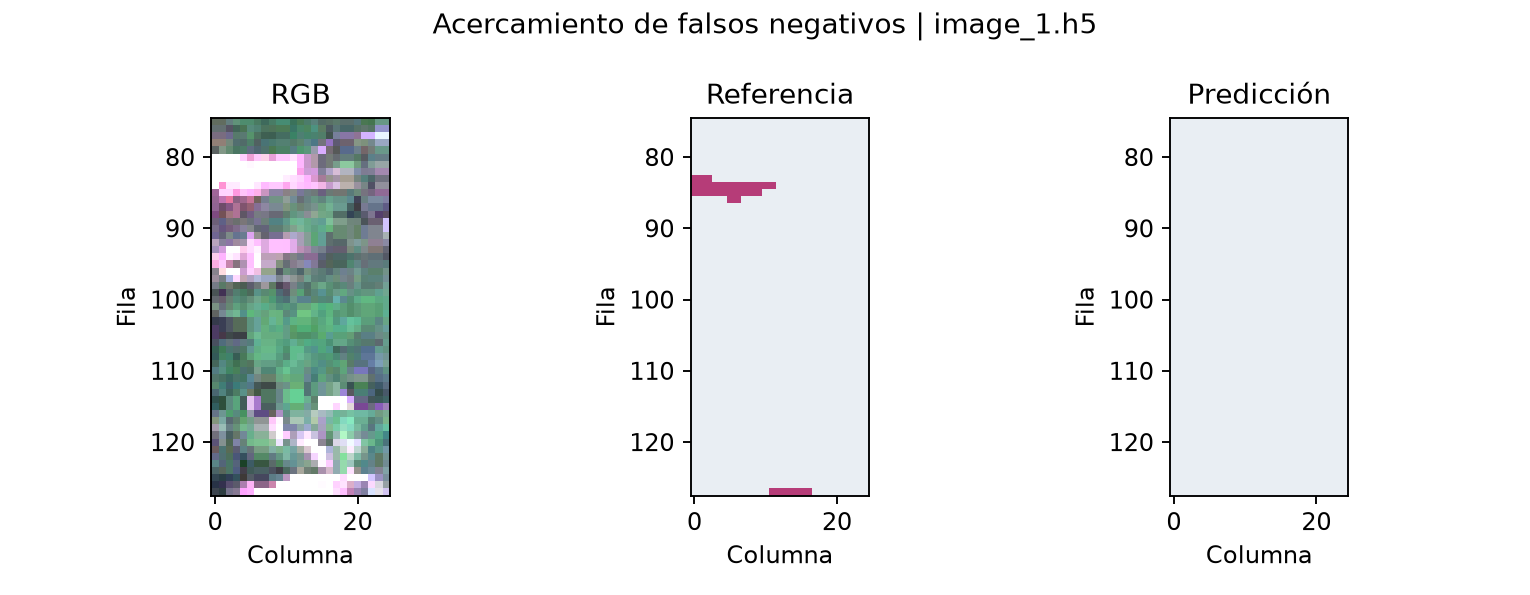

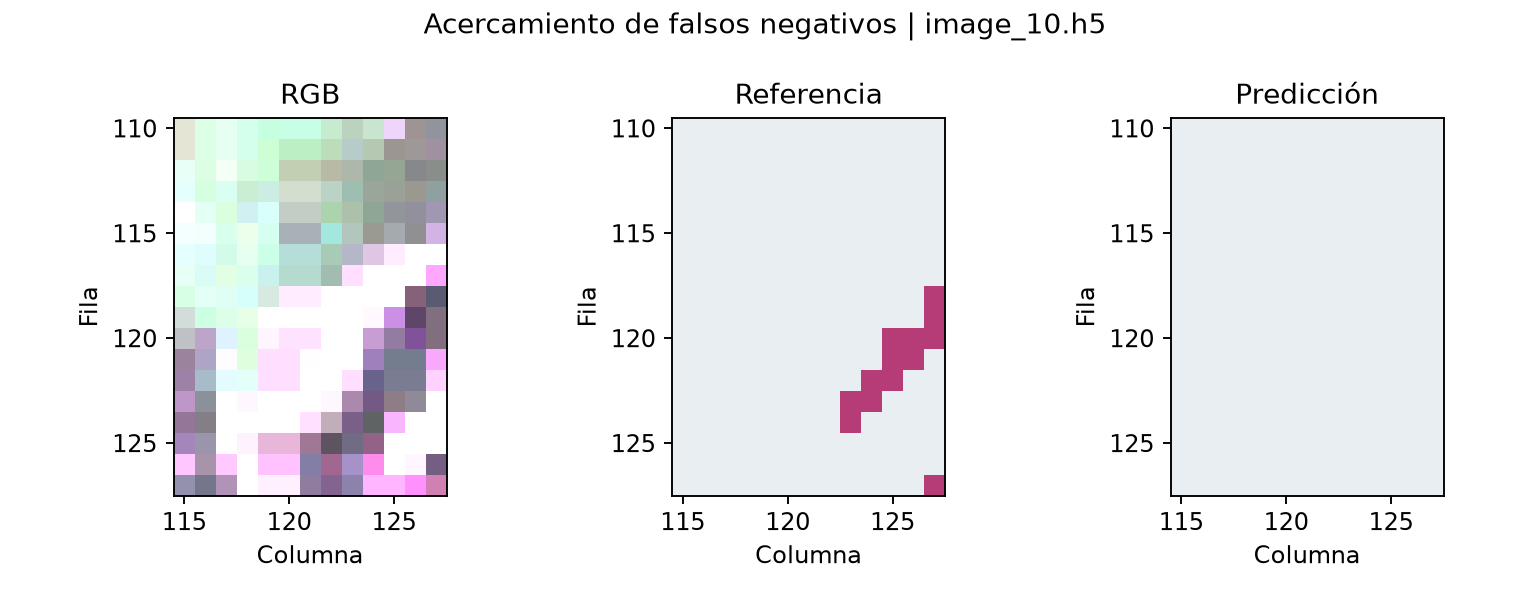

In [11]:
import shutil
shutil.copy2(ROOT/'datos'/'manifest.json',OUT/'manifest_datos.json')
"""Diagnóstico trazable del piloto docente; no ajusta el modelo ni usa test para selección."""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


def auditar(root, out):
    from prithvi_taller import read_sample, patch_labels, sha256
    root, out = Path(root), Path(out)
    manifest = json.loads((out / 'manifest_datos.json').read_text(encoding='utf-8'))
    records, patches, cases = [], [], []
    split_hashes = {'train': set(), 'test': set()}
    for entry in manifest['samples']:
        split = entry['split']
        image = root / 'datos' / 'images' / split / Path(entry['image']).name
        mask = root / 'datos' / 'annotations' / split / Path(entry['label']).name
        assert sha256(image) == entry['image_sha256']
        assert sha256(mask) == entry['label_sha256']
        split_hashes[split].add(entry['image_sha256'])
        x, y = read_sample('deslizamientos', image, mask)
        valid = y >= 0
        yy, xx = np.where(y == 1)
        records.append(dict(split=split, image=image.name, mask=mask.name,
            valid=int(valid.sum()), positive=int((y == 1).sum()),
            ignored=int((~valid).sum()), positive_fraction=float((y == 1).sum()/valid.sum()),
            positive_bbox=str([int(yy.min()), int(xx.min()), int(yy.max()), int(xx.max())]) if len(yy) else 'absent'))
        pl = patch_labels(y)
        for r in range(14):
            for c in range(14):
                block = y[r*16:(r+1)*16, c*16:(c+1)*16]
                n = int((block >= 0).sum())
                if n:
                    patches.append(dict(split=split, image=image.name, row=r, column=c,
                        valid=n, positive=int((block == 1).sum()),
                        positive_fraction=float((block == 1).sum()/n), target=int(pl[r,c])))
        if split != 'test':
            continue
        i = sum(z['split'] == 'test' for z in records)-1
        saved = np.load(out / f'escena_{i}.npz')
        assert np.array_equal(y, saved['label'])
        pred = saved['prediction']
        error = np.zeros(y.shape, dtype=int)
        error[(y == 1) & (pred == 0)] = 1
        error[(y == 0) & (pred == 1)] = 2
        error[(y == 1) & (pred == 1)] = 3
        for typ, condition in [('TN', (y == 0) & (pred == 0)), ('FN', (y == 1) & (pred == 0)),
                               ('FP', (y == 0) & (pred == 1)), ('TP', (y == 1) & (pred == 1))]:
            rows, cols = np.where(condition)
            cases.append(dict(scene=i, image=image.name, case=typ, pixels=len(rows),
                example_row=int(rows[len(rows)//2]) if len(rows) else -1,
                example_column=int(cols[len(rows)//2]) if len(rows) else -1))
        rgb = x[[2,1,0],0].transpose(1,2,0).copy()[:128,:128]
        for channel in range(3):
            lo, hi = np.percentile(rgb[:,:,channel], [2,98])
            rgb[:,:,channel] = np.clip((rgb[:,:,channel]-lo)/max(hi-lo,1e-6),0,1)
        fig, ax = plt.subplots(1,4,figsize=(13,3.8))
        ax[0].imshow(rgb); ax[0].set_title('RGB de visualización')
        cm = ListedColormap(['#e9eef3','#b63c78'])
        ax[1].imshow(y[:128,:128], cmap=cm, vmin=0,vmax=1); ax[1].set_title('Referencia 0 / 1')
        ax[2].imshow(pred[:128,:128], cmap=cm,vmin=0,vmax=1); ax[2].set_title('Predicción 0 / 1')
        ax[3].imshow(error[:128,:128], cmap=ListedColormap(['#e9eef3','#d43e38','#f4a340','#247c50']),vmin=0,vmax=3)
        ax[3].set_title('Mapa de errores')
        for a in ax:
            a.set_xlabel('Columna (base cero)'); a.set_ylabel('Fila (base cero)')
        fig.suptitle(f'Test {i}: {image.name} | {int((y==1).sum())} píxeles positivos')
        fig.legend(handles=[Patch(color='#d43e38',label='Falso negativo'),Patch(color='#f4a340',label='Falso positivo'),Patch(color='#247c50',label='Verdadero positivo')],loc='lower center',ncol=3,frameon=False,bbox_to_anchor=(.5,.01))
        fig.tight_layout(rect=(0,.19,1,.94)); fig.savefig(out/f'04_trazabilidad_{i}.png',dpi=170); plt.close(fig)
        # Acercamiento con idéntica extensión para distinguir objetos pequeños.
        if len(yy):
            r0,r1=max(0,int(yy.min())-8),min(128,int(yy.max())+9)
            c0,c1=max(0,int(xx.min())-8),min(128,int(xx.max())+9)
            fig, ax = plt.subplots(1,3,figsize=(9,3.5))
            extent=(c0-.5,c1-.5,r1-.5,r0-.5)
            for a, arr, title in zip(ax,[rgb[r0:r1,c0:c1],y[r0:r1,c0:c1],pred[r0:r1,c0:c1]],['RGB','Referencia','Predicción']):
                if arr.ndim==3:a.imshow(arr,extent=extent)
                else:a.imshow(arr,cmap=cm,vmin=0,vmax=1,extent=extent,interpolation='nearest')
                a.set_title(title);a.set_xlabel('Columna');a.set_ylabel('Fila')
            fig.suptitle(f'Acercamiento de falsos negativos | {image.name}')
            fig.tight_layout();fig.savefig(out/f'05_detalle_FN_{i}.png',dpi=170);plt.close(fig)
    assert not split_hashes['train'] & split_hashes['test'], 'Imágenes duplicadas entre train y test'
    pd.DataFrame(records).to_csv(out/'inventario_muestras.csv',index=False)
    df=pd.DataFrame(patches);df.to_csv(out/'diagnostico_parches.csv',index=False)
    pd.DataFrame(cases).to_csv(out/'casos_errores.csv',index=False)
    train=df[df.split=='train']
    diagnostic=dict(train_patch_targets={str(int(k)):int(v) for k,v in train[train.target>=0].target.value_counts().items()},
        max_train_positive_fraction=float(train.positive_fraction.max()),
        train_test_duplicate_images=False,
        metadata='HDF5 sin atributos de fecha, CRS, geotransformación ni identificador de evento; no se acredita independencia por evento.',
        channel_contract='Selección docente [1,2,3,8,10,11]. La descripción pública de 12 bandas no identifica inequívocamente B8A; pendiente confirmación docente.',
        teacher_confirmation='Pendiente de evidencia',
        interpretation='La falta de clase positiva en la cabeza impide evaluar la capacidad discriminativa de Prithvi para deslizamientos.')
    (out/'diagnostico.json').write_text(json.dumps(diagnostic,ensure_ascii=False,indent=2),encoding='utf-8')
    print(json.dumps(diagnostic,ensure_ascii=False,indent=2))
    return diagnostic



auditar(ROOT,OUT)
for i in range(2):
    display(__import__("IPython").display.Image(filename=str(OUT/f"05_detalle_FN_{i}.png")))


## 5 Implementación y protocolo experimental

Se cargan los pesos Prithvi_100M.pt de la revisión 7b231fe5b0684e2ddd40c967fbc02e225ef77dc6 del repositorio oficial [2]. La ejecución local utiliza CPU. El cuaderno registra versiones, revisión, dispositivo y configuración; el script conserva la misma ruta. Se corrigió la lectura del YAML plano para obtener seis canales de entrada y se fijó también la revisión del dataset.

El encoder recibe 224 por 224 píxeles, produce una cuadrícula de 14 por 14 tokens de 768 componentes y recupera el orden espacial de los tokens del MAE. Cada token corresponde a un parche de 16 por 16. La etiqueta de entrenamiento es la clase mayoritaria de sus píxeles válidos, si al menos el 50 por ciento del parche es válido. En un empate de clases, np.argmax selecciona la primera clase, 0: el empate no produce un positivo.

La cabeza es un Random Forest con 80 árboles, profundidad máxima 10, ponderación balanced y semilla 42. Sus decisiones se mantienen como en el flujo revisado y no se seleccionan usando test. La predicción de cada parche se repite sobre sus 256 píxeles. La línea base predice siempre 0 porque en entrenamiento hay 64617 píxeles de fondo frente a 919 positivos, equivalentes a 98.598 y 1.402 por ciento.

El entrenamiento contiene 256 parches válidos y todos se etiquetan como fondo. La mayor fracción positiva observada es 0.3984375, inferior a la mayoría necesaria. La ponderación de clases no puede recuperar una clase que no está presente en los objetivos. La distribución completa por parche se conserva en diagnostico_parches.csv.



## 6 Evaluación cuantitativa

La agregación principal es la media aritmética por escena, como exige el enunciado. La agregación global por píxeles se presenta por separado. Para cada clase se calcula IoU = TP / (TP + FP + FN), F1 = 2TP / (2TP + FP + FN), precisión = TP / (TP + FP) y recall = TP / (TP + FN). Ambos métodos utilizan exactamente la misma máscara de posiciones válidas.

Cuando la unión es cero, IoU y F1 son NaN y esa escena se excluye de la media de esa métrica; se informa el número de escenas definidas. El recall es NaN si no hay referencia positiva. Si hay referencia positiva pero no predicciones positivas, la precisión se reporta como 0 por convención del módulo docente. Si no hay referencia ni predicción de la clase, la precisión es NaN. Aquí las dos escenas tienen positivos y las cuatro métricas están definidas para ambas.

| Método | IoU media por escena | F1 media por escena | Precisión media | Recall medio | Escenas |
| --- | ---: | ---: | ---: | ---: | ---: |
| Prithvi y RF | 0.000 | 0.000 | 0.000 | 0.000 | 2 |
| Línea base clase 0 | 0.000 | 0.000 | 0.000 | 0.000 | 2 |

Los resultados globales de la clase positiva también son 0 para ambos métodos. La prueba contiene 32722 píxeles de fondo y 46 positivos, 0.1404 por ciento del total. La exactitud global es 99.8596 por ciento pese a que no se detecta ningún positivo; por eso no es la métrica principal.

| Método y clase | Soporte global | IoU global | F1 global | Precisión global | Recall global |
| --- | ---: | ---: | ---: | ---: | ---: |
| Prithvi y RF fondo | 32722 | 0.998596 | 0.999298 | 0.998596 | 1.000000 |
| Prithvi y RF deslizamiento | 46 | 0.000000 | 0.000000 | 0.000000 | 0.000000 |
| Línea base fondo | 32722 | 0.998596 | 0.999298 | 0.998596 | 1.000000 |
| Línea base deslizamiento | 46 | 0.000000 | 0.000000 | 0.000000 | 0.000000 |

La matriz global es idéntica para ambos métodos: filas = referencia, columnas = predicción.

| Referencia | Predicho fondo | Predicho deslizamiento |
| --- | ---: | ---: |
| Fondo | 32722 | 0 |
| Deslizamiento | 46 | 0 |

El CSV metricas.csv corresponde a agregación global; metricas_media_por_escena.csv es la tabla principal. metricas_por_escena.csv y metricas_por_clase.csv permiten reconstruir ambas. Las predicciones y las máscaras se conservan en escena_0.npz y escena_1.npz.



## 7 Figuras y análisis de errores

Las figuras usan los datos reales, igual extensión espacial y leyenda explícita. Las imágenes tienen solo 128 por 128 píxeles: exportar a mayor resolución mejora textos y contornos, pero no añade detalle satelital. Se conserva el RGB observado sin generar texturas ni modificar etiquetas. Los paneles completos muestran la extensión válida; los acercamientos conservan índices de fila y columna.

![Entrada y referencia de entrenamiento](entregables/01_exploracion.png)

| Caso | Muestra | Evidencia y ubicación base cero |
| --- | --- | --- |
| Acierto de fondo | Test image_1.h5 | 16351 TN; ejemplo fila 63 columna 111 |
| Falso negativo | Test image_1.h5 | 33 FN; ejemplo fila 85 columna 1; caja de positivos filas 83 a 127 y columnas 0 a 16 |
| Falso negativo | Test image_10.h5 | 13 FN; ejemplo fila 121 columna 126; caja de positivos filas 118 a 127 y columnas 123 a 127 |

No existen falsos positivos ni verdaderos positivos en estas dos escenas. Se analizan dos omisiones distintas y un acierto de fondo, de acuerdo con la excepción del enunciado para categorías inexistentes. No se presentan como aciertos de detección los verdaderos negativos.

![Resultados y errores de test 0](entregables/04_trazabilidad_0.png)

![Acercamiento de errores de test 1](entregables/05_detalle_FN_1.png)

El fallo comprobado está en la generación de objetivos de la cabeza: la mayoría por parche elimina la clase rara. Los objetos pequeños y los bordes quedan además limitados por la salida constante de cada parche. No puede atribuirse este resultado exclusivamente al encoder ni inferirse su rendimiento con una cabeza que sí haya visto positivos.

Una carretera, cantera u obra puede parecerse a una cicatriz por el suelo expuesto, el contraste y la geometría. Sombras, vegetación y nubes pueden ocultar rasgos. Estos son factores a investigar, no errores semánticos demostrados aquí: el clasificador constante no permite identificar confusiones específicas con carreteras o canteras. Sin inventario geográfico o validación experta tampoco se cuantifica la calidad de las etiquetas ni el desplazamiento regional.



## 8 Transferencia a Colombia

Proponemos estudiar una región montañosa de Antioquia con inventarios locales fechados y revisados por expertos, imágenes Sentinel 2 compatibles y máscaras por evento. Se necesitarían fechas de adquisición, CRS, resolución, nubosidad y cobertura espacial, además de pendiente y elevación. Una imagen anterior permitiría distinguir cambios recientes de suelo ya descubierto. Este planteamiento no se ejecutó con datos colombianos.

La primera adaptación sería asegurar bandas y escala compatibles. La topografía se incorporaría mediante una rama auxiliar o una arquitectura expresamente ajustada; no se introduciría como si fuese una banda óptica. Para preservar objetos pequeños se evaluaría una cabeza de segmentación de mayor resolución o una regla alternativa de objetivos, previa autorización del docente para cambiar el flujo.

La partición debe separar regiones y eventos completos, con margen espacial cuando proceda. Entrenamiento y validación servirían para ajustar hiperparámetros y umbrales; una prueba independiente se reservaría hasta cerrar el método. Se medirían IoU, F1, precisión y recall por evento, soporte y desempeño según tamaño del deslizamiento. El criterio de éxito sería superar la línea base en prueba, con recall útil y precisión revisada por expertos. Los umbrales operativos se acordarían según el costo de omisiones y falsas alarmas, sin inventar un umbral universal.



## 9 Consideraciones éticas y limitaciones

Un falso negativo puede ocultar daño y un falso positivo puede desviar recursos. La revisión experta y la validación regional son necesarias antes de cualquier decisión. No se presenta el piloto como mapa oficial, producto operativo, alerta temprana ni predicción de eventos.

El tamaño 4/2, la prevalencia positiva extrema, el relleno artificial, la resolución por parche y la falta de metadatos limitan las conclusiones. No se puede demostrar independencia por evento solo por conservar las carpetas del espejo. El contrato de canales y escala sigue sin confirmación docente. La disponibilidad pública del espejo no demuestra autorización irrestricta para redistribuir los datos: se enlazan las fuentes y se excluyen pesos y escenas crudas del paquete de entrega.

Se deben respetar licencias de código, datos y pesos. La referencia comunitaria srivassid/prithvi-landslide suministrada en la ficha no se utilizó como checkpoint ni se presenta como modelo oficial IBM NASA. Las limitaciones de este piloto no pueden ocultarse mediante una selección favorable de escenas, ajustes sobre test o embellecimiento de las imágenes.



## 10 Conclusiones del piloto

El flujo se ejecuta y evalúa sobre las mismas posiciones válidas para el modelo y la línea base. Ambos obtienen IoU y F1 de deslizamiento iguales a 0, tanto por escena como globalmente. La exactitud alta del fondo no demuestra éxito en la aplicación.

El diagnóstico muestra que los 919 píxeles positivos de entrenamiento desaparecen como clase de parche: los 256 objetivos son fondo. Esta es una explicación verificable de las 46 omisiones de prueba. El estudio no prueba ni descarta la capacidad de Prithvi con una adaptación adecuada.

El piloto motivó ampliar el entrenamiento, separar validación y estudiar otras cabezas. La sección 12 presenta esa ampliación ejecutada y sus límites. El resultado negativo original se conserva como evidencia del flujo suministrado; la ampliación no acredita todavía desempeño alto ni sustituye la confirmación docente del contrato de entrada.



## 11 Referencias en formato IEEE

[1] J. Jakubik et al., “Foundation Models for Generalist Geospatial Artificial Intelligence,” arXiv:2310.18660, 2023. Disponible: https://arxiv.org/abs/2310.18660

[2] IBM NASA Geospatial, “Prithvi EO 1.0 100M,” repositorio de modelo, revisión 7b231fe5b0684e2ddd40c967fbc02e225ef77dc6. Disponible: https://huggingface.co/ibm-nasa-geospatial/Prithvi-EO-1.0-100M

[3] O. Ghorbanzadeh et al., “Landslide4Sense: Reference Benchmark Data and Deep Learning Models for Landslide Detection,” IEEE Transactions on Geoscience and Remote Sensing, vol. 60, pp. 1-17, 2022, doi: 10.1109/TGRS.2022.3215209. Disponible: https://arxiv.org/abs/2206.00515. Documentación del conjunto: https://github.com/iarai/Landslide4Sense-2022

[4] sasmit545, “Landslide4sense,” Hugging Face Datasets, espejo de datos, revisión 8508a55feceb5653a085d6be64ef9217710f7c00. Disponible: https://huggingface.co/datasets/sasmit545/Landslide4sense

[5] D. Szwarcman et al., “Prithvi EO 2.0: A Versatile Multi Temporal Foundation Model for Earth Observation Applications,” arXiv:2412.02732, 2024. Disponible: https://arxiv.org/abs/2412.02732

[6] NASA IMPACT, “HLS Foundation Models,” repositorio de código. Disponible: https://github.com/NASA-IMPACT/hls-foundation-os

[7] E. E. Zurek Varela, “Enunciado general Prithvi aplicado a problemas geoespaciales,” “Grupo 2 detección de deslizamientos” y notebook guía del Grupo 2, material docente, Inteligencia Artificial, 2026.

Fuentes web consultadas el 17 de noviembre de 2026. Las fuentes [1] y [3] son publicaciones primarias; [2] identifica el modelo realmente utilizado. Los archivos manifest_datos.json, procedencia.json e inventario_muestras.csv conservan la trazabilidad de esta ejecución.


## Exportación
El ZIP contiene evidencias y máscaras derivadas. Los pesos y las escenas originales se descargan desde sus fuentes para repetir el experimento.

In [12]:
import shutil
save_json(OUT/'verificacion_ejecucion.json', {'execution':'notebook completo en orden', 'methods':summary.to_dict(orient='records'), 'main_aggregation':'mean_per_scene', 'teacher_confirmation':'Pendiente de evidencia'})
delivery=BASE/'entregables'
delivery.mkdir(exist_ok=True)
for p in OUT.iterdir():
    if p.is_file(): shutil.copy2(p,delivery/p.name)
evidence=shutil.make_archive(str(ROOT/'evidencias'),'zip',OUT)
print('Evidencias guardadas:', evidence)


Evidencias guardadas: C:\Users\Cgalv\Desktop\github repositories\prithvi-deslizamiento\taller_deslizamientos\evidencias.zip


## 12 Ampliación experimental para superar el piloto constante

Se ejecutó una ampliación complementaria el 17 de noviembre de 2026, conservando el piloto original como evidencia del flujo suministrado. La selección de archivos se fijó antes de leer sus etiquetas: 96 escenas de train, 24 de validación y 32 de test, con semilla 20261117 y la misma revisión del espejo. Se excluyeron las seis escenas previamente utilizadas. Las particiones proceden del proveedor y no contienen imágenes idénticas por SHA256 entre sí; no se acredita independencia por evento o región porque faltan metadatos.

### Método y selección sin usar test

Se mantuvieron el encoder Prithvi congelado, los seis índices de canal del lector y la normalización estimada exclusivamente con entrenamiento. La ampliación contiene 40699 píxeles positivos y 1532165 de fondo. Con la regla mayoritaria original se obtienen 70 parches positivos y 6074 negativos, en lugar de cero positivos. El RF conserva 80 árboles, profundidad 10, ponderación balanced y semilla 42. El umbral 0.1 fue elegido en validación; el umbral estándar 0.5 también se reporta.

Antes de abrir test se compararon tres reglas exploratorias de ocupación positiva por parche, mayores que 5, 10 y 20 por ciento, y una cabeza por píxel. La variante por parche elegida en validación fue ocupación mayor que 10 por ciento con umbral 0.55. Las reglas de ocupación no son la regla mayoritaria de la guía y se identifican como modificaciones experimentales.

La cabeza por píxel utiliza seis bandas normalizadas y 32 componentes PCA de los embeddings de Prithvi. El PCA se ajusta solo sobre tokens válidos de train. Se interpolan características continuas para llevarlas a la cuadrícula de píxeles; las etiquetas categóricas no se interpolan. Se toman hasta 512 píxeles reales de cada clase por escena de entrenamiento, sin reemplazo y con semilla 42: 66306 en total. Un RF de 100 árboles y profundidad 20 aprende esa cabeza. Su umbral 0.55 se selecciona en validación. Como control se entrena una cabeza equivalente con solo las seis bandas ópticas, cuyo umbral de validación es 0.75.

El F1 medio de validación fue 0.1968 para el RF mayoritario validado, 0.2496 para la ocupación 10%, 0.3371 para la cabeza Prithvi y óptico por píxel, y 0.2689 para el control óptico. La variante con Prithvi elegida por F1 de validación fue la cabeza por píxel. Se guardaron configuraciones y sus hashes antes de evaluar test. No se volvió a ajustar después de abrirlo. Seleccionar umbrales en un conjunto separado evita confundir ajuste y evaluación [8].

### Resultados sobre las mismas 32 escenas nuevas

| Método | IoU media | F1 media | IoU global | F1 global | Escenas F1 definidas |
| --- | ---: | ---: | ---: | ---: | ---: |
| Línea base constante 0 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 26 |
| Prithvi RF mayoritario 0.5 | 0.0141 | 0.0246 | 0.1123 | 0.2018 | 28 |
| Prithvi RF mayoritario validado | 0.1323 | 0.1944 | 0.3714 | 0.5417 | 30 |
| Prithvi RF ocupación 10% | 0.1075 | 0.1687 | 0.2839 | 0.4422 | 29 |
| Prithvi y óptico por píxel | 0.2030 | 0.3068 | 0.2422 | 0.3900 | 31 |
| Solo óptico por píxel | 0.2098 | 0.2986 | 0.4533 | 0.6238 | 32 |

La prueba contiene 524288 posiciones válidas, de las cuales 26089 son deslizamiento y 498199 son fondo. Hay 26 escenas con referencia positiva y seis sin positivos. La media por escena sigue siendo la agregación principal. Cuando una escena no tiene referencia ni predicción positiva, su IoU y F1 son indefinidos y se excluyen; si sí hay falsos positivos, sus IoU y F1 son 0. Por eso el número de escenas definidas varía entre métodos y se muestra explícitamente. Los CSV conservan también precisión, recall y soporte por clase y escena.

![Comparación de los métodos en prueba nueva](experimentos/mejora_rf/resultados/comparacion_final.png)

La cabeza por píxel con Prithvi mejora el F1 medio frente al RF mayoritario validado, pero su IoU global y F1 global son inferiores. El control óptico obtiene mayor IoU media y mejores métricas globales que la cabeza con Prithvi. Por tanto, no se demuestra superioridad general de añadir Prithvi: el resultado depende de la agregación y de la distribución del tamaño de los objetos. No se elige retrospectivamente el modelo por su puntuación de test ni se oculta el control óptico.

El RF mayoritario validado logra F1 global 0.5417, pero F1 medio por escena 0.1944; ambas cifras describen fenómenos distintos. No sería correcto destacar solo la cifra global para aparentar mejor cumplimiento de la agregación que exige el profesor. Los resultados ya no son constantes en cero, pero el desempeño sigue siendo moderado y desigual entre escenas.

### Casos reales y límites de la mejora

Se incluyen tres escenas distintas seleccionadas con criterios diagnósticos explícitos: mayor número de verdaderos positivos, falsos positivos y falsos negativos, respectivamente, entre escenas aún no mostradas. La selección sirve para analizar aciertos y fallos después de evaluar; no intervino en el entrenamiento ni en la selección de la cabeza. El detalle se conserva en seleccion_casos.json y casos_test.csv.

![Caso con verdaderos positivos de la cabeza por píxel](experimentos/mejora_rf/resultados/caso_aciertos.png)

![Caso con falsos positivos de la cabeza por píxel](experimentos/mejora_rf/resultados/caso_falsos_positivos.png)

![Caso con falsos negativos de la cabeza por píxel](experimentos/mejora_rf/resultados/caso_falsos_negativos.png)

La matriz global de la cabeza con Prithvi por píxel contiene 481507 TN, 16692 FP, 15727 FN y 10362 TP. Ya detecta áreas positivas, pero mantiene omisiones importantes y falsas alarmas. La mejora no convierte el piloto en un producto operativo.

### Relación con la entrega solicitada

El notebook conserva la ejecución original solicitada y añade esta comparación complementaria. El RF mayoritario ampliado conserva encoder congelado, clasificador ligero por parche, línea base de entrenamiento y evaluación con máscara válida común; cambia la cantidad de escenas e incorpora validación. Las reglas de ocupación y la cabeza por píxel cambian el flujo docente y se presentan como extensiones exploratorias, pendientes de aceptación si se desean usar como método principal. La confirmación de canales, escala, normalización y pesos sigue pendiente para todas las variantes.

La ampliación demuestra que más datos y validación permiten salir del clasificador constante sin usar test para seleccionar. No demuestra todavía desempeño alto ni una mejora universal de Prithvi sobre las bandas ópticas. Un desarrollo posterior deberá reservar una prueba nueva y mayor, confirmar el contrato de entrada y reforzar la representación de objetos y eventos, en vez de seguir ajustando estas 32 escenas ya examinadas.

[8] scikit-learn developers, “Tuning the decision threshold for class prediction,” documentación oficial, consultada el 17 de noviembre de 2026. Disponible: https://scikit-learn.org/stable/modules/classification_threshold.html


### Inspección y reproducción de la ampliación
Las siguientes salidas se leen de archivos producidos por la ejecución real de los scripts incluidos. Los modelos se eligieron con validación, antes de evaluar test. El lector no vuelve a entrenar ni selecciona usando test. Para repetir el entrenamiento, siga REPRODUCIR_MEJORA.md.

,method,iou,f1,precision,recall,escenas_f1_definidas,iou_global,f1_global,support
0,baseline,0.000000,0.000000,0.000000,0.000000,26,0.000000,0.000000,26089
1,prithvi_rf_05,0.014101,0.024550,0.060268,0.018068,28,0.112250,0.201844,26089
2,prithvi_rf_validado,0.132328,0.194354,0.158946,0.430479,30,0.371450,0.541689,26089
3,dense_optical_only,0.209786,0.298578,0.256036,0.686001,32,0.453250,0.623775,26089
4,dense_prithvi_optical,0.203004,0.306760,0.291069,0.600573,31,0.242210,0.389967,26089
5,patch_occupancy_010,0.107502,0.168734,0.142347,0.348358,29,0.283873,0.442214,26089


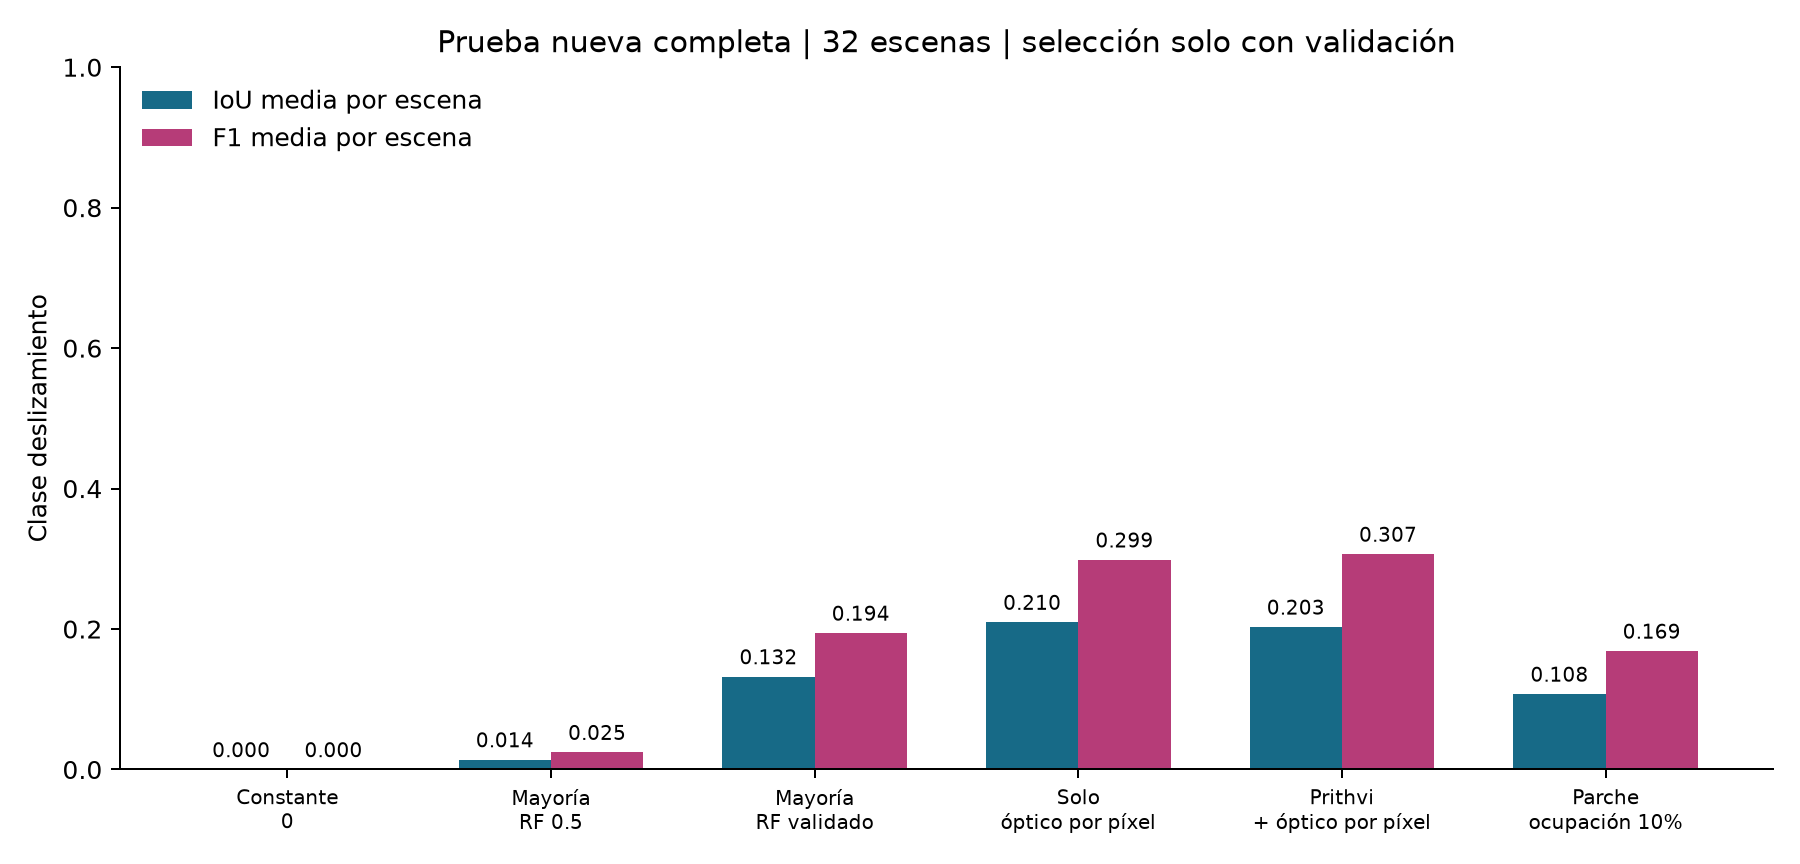

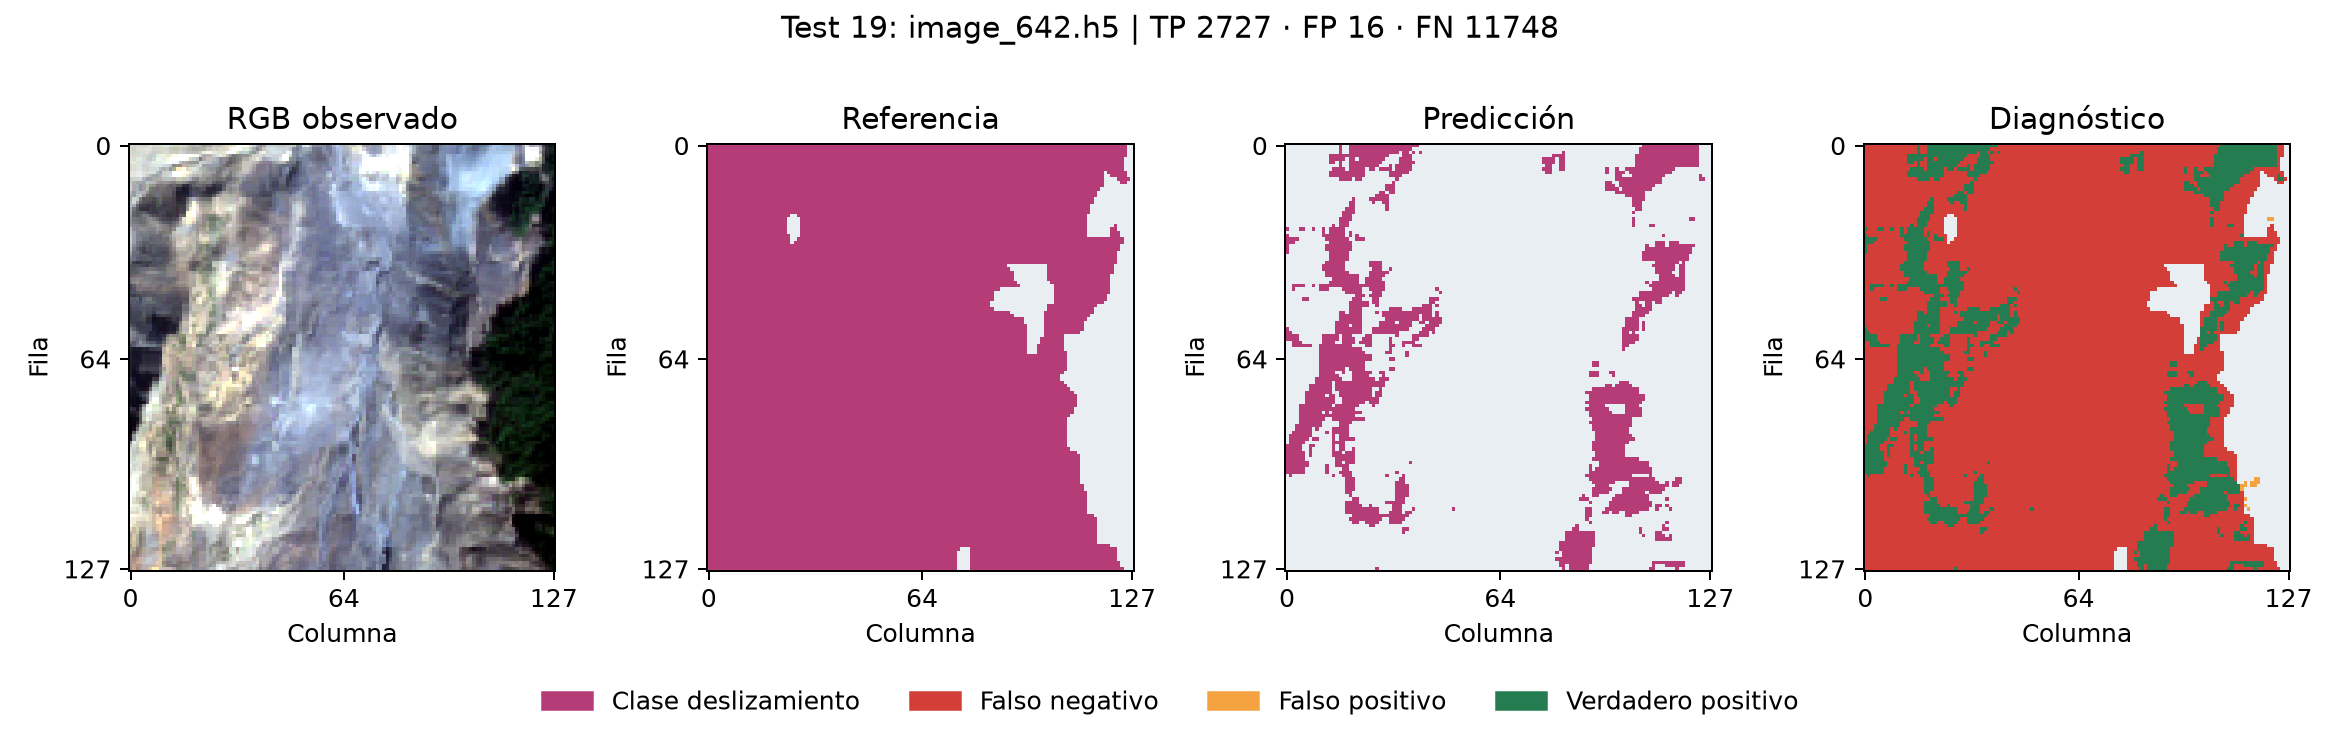

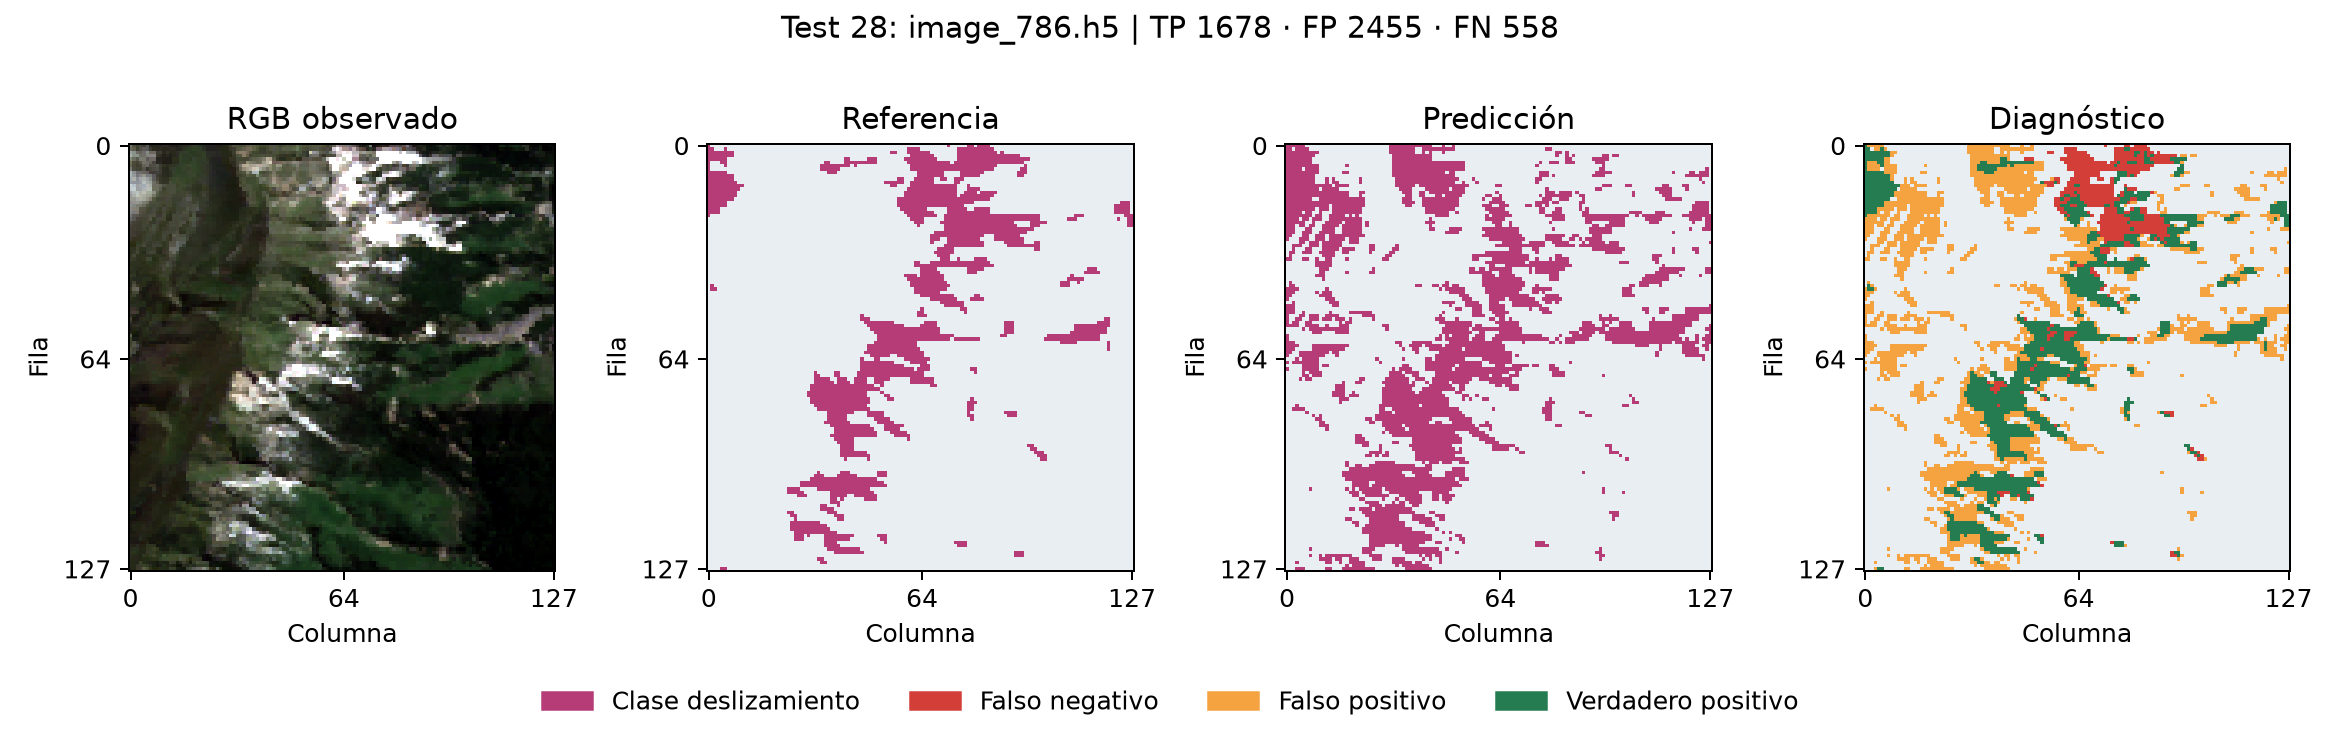

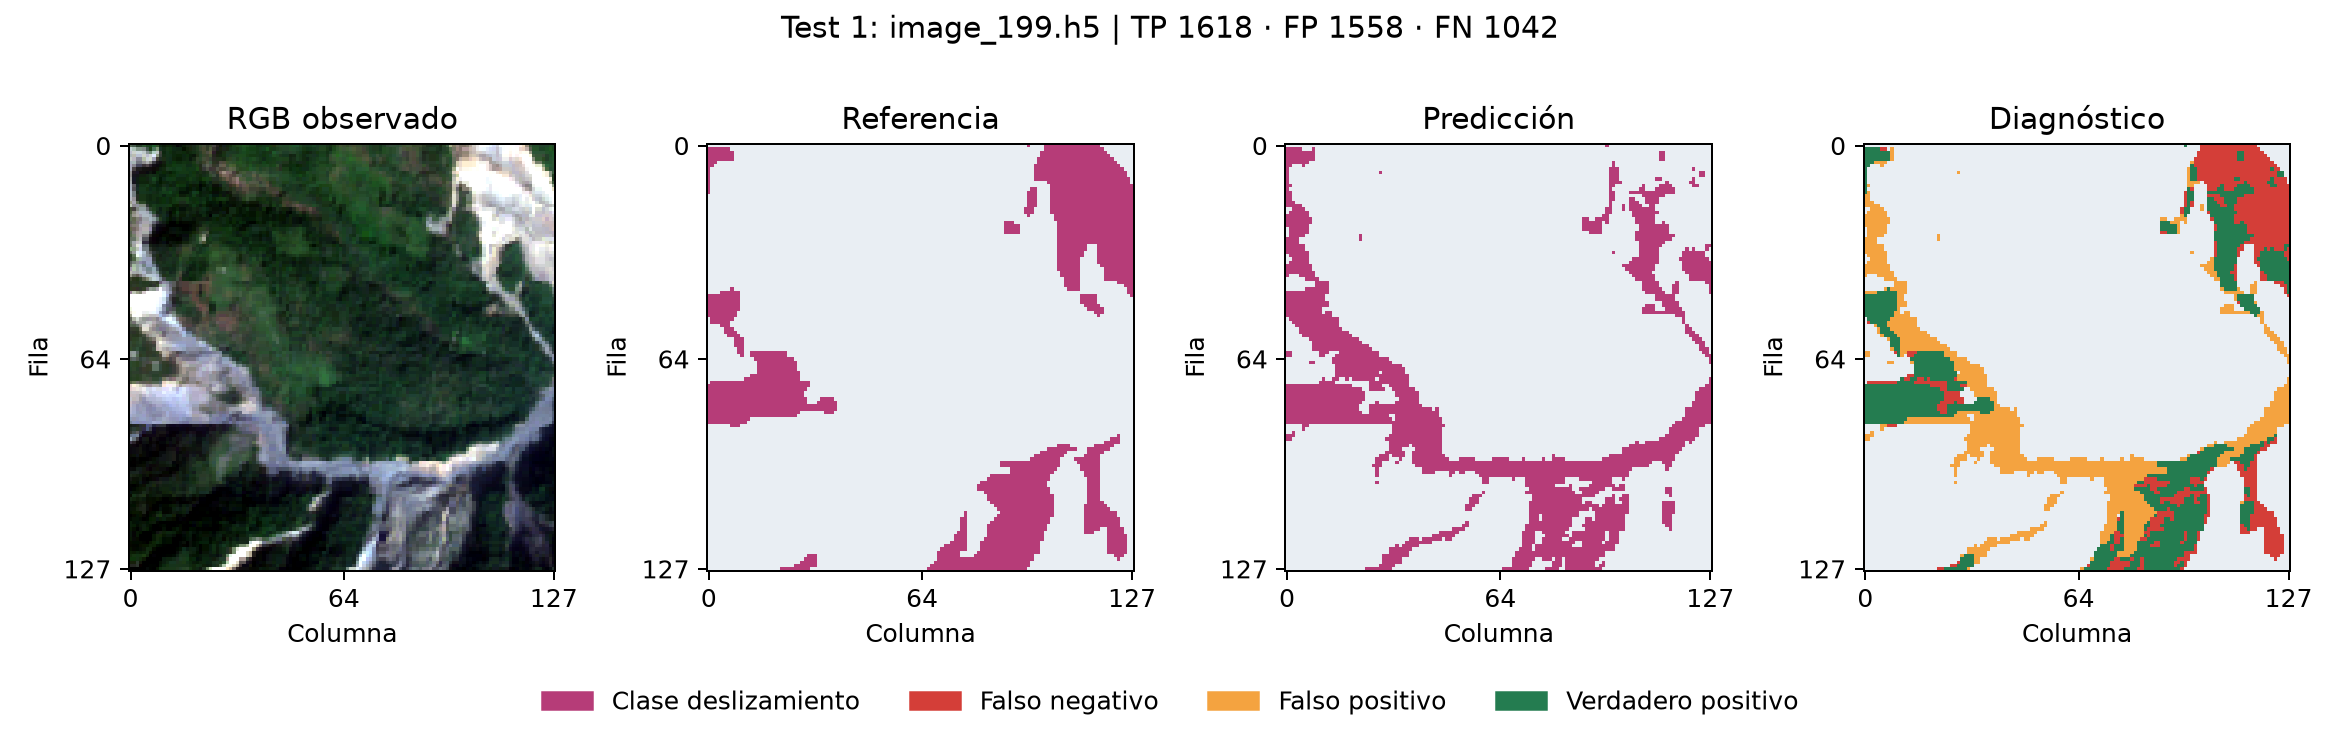

Selección congelada antes de test; comprobaciones independientes con verificar_mejora.py.


In [13]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
MEJORA=Path('experimentos/mejora_rf/resultados')
if MEJORA.exists():
    display(pd.read_csv(MEJORA/'comparacion_final.csv'))
    for name in ['comparacion_final.png','caso_aciertos.png','caso_falsos_positivos.png','caso_falsos_negativos.png']:
        display(Image(filename=str(MEJORA/name)))
    print('Selección congelada antes de test; comprobaciones independientes con verificar_mejora.py.')
else:
    print('La ampliación requiere el repositorio completo; su ejecución se documenta en REPRODUCIR_MEJORA.md.')
